# Project 1 – Detecting Moving Objects in DAS Recordings
🇹🇷 *Proje 1 – DAS Kayıtlarında Hareketli Nesneleri Tespit Etme*

**Ekip:** Ceyda (ER2347), Sema (ER2337)  
**Hedef not:** 4+ → gerçek DAS verisi  
**Teslim:** 22.11.2026 23:59 · **Sunum:** 26.11.2026 / 01.12.2026

> ℹ️ Bu dosya **rapor şablonudur**. Bölümler adım adım, anlaşılarak doldurulacak; sonra İngilizceye çevrilip detaylandırılacak.

## 0. Genel kurallar (tüm proje boyunca geçerli)

**📄 PDF gereksinimleri**

> *"The implementation of the algorithm must be created in Python with use the following image processing libraries: OpenCV, NumPy, Matplotlib, Pillow, and Skimage. If You want to use other libraries, consult by e-mail (do not use neural networks or external tools)."* (s.4)  
> 🇹🇷 *Algoritma Python ile ve şu görüntü işleme kütüphaneleri kullanılarak yazılmalı: OpenCV, NumPy, Matplotlib, Pillow ve Skimage. Başka kütüphane kullanmak isterseniz e-postayla danışın (sinir ağı veya harici araç kullanmayın).*
>
> *"the approach should be general, and you cannot directly hardcode the position of lines or any elements directly related to specific individual lines."* (s.5)  
> 🇹🇷 *yaklaşım genel olmalı; çizgilerin konumunu veya tek tek belirli çizgilerle doğrudan ilgili hiçbir öğeyi koda doğrudan yazamazsınız.*
>
> *"All sources of data, code and inspiration must be reported with a description of what was used."* (s.4)  
> 🇹🇷 *Kullanılan tüm veri, kod ve ilham kaynakları, neyin kullanıldığı açıklanarak belirtilmelidir.*

**⚠️ Her bölümde kontrol et**
- Sadece **NumPy, Matplotlib, OpenCV, scikit-image, Pillow** (+ Python'un kendi modülleri: `os`, `glob`, `datetime`). **pandas / SciPy / sklearn yok.**
- **Sinir ağı / yapay zeka modeli yok**, harici araç yok.
- **Hardcode yok:** çizgi konumu veya belirli bir araca özel değer koda yazılmaz. Eşikler veriden otomatik hesaplanır.
- **Vektörize kod**, piksel piksel `for` döngüsü yok. (s.6: *"use of vectorized operations instead of unnecessary pixel-by-pixel loops"* 🇹🇷 *gereksiz piksel piksel döngüler yerine vektörize işlemler kullanılması*)
- Kod **hatasız ve uyarısız** çalışmalı. (s.6: *"code execution without errors or warnings"* 🇹🇷 *kodun hatasız ve uyarısız çalışması*)
- Kod **eksiksiz** olmalı, veri yükleme dahil baştan sona çalışmalı. (s.6: *"Completeness of the source code required to run the application (e.g., data loading and preparation)"* 🇹🇷 *uygulamayı çalıştırmak için gereken kaynak kodun eksiksiz olması (ör. veri yükleme ve hazırlama)*)
- **Okunabilir kod + yorum satırları.** (s.6: *"Code readability, organization, and quality of comments"* 🇹🇷 *kodun okunabilirliği, düzeni ve yorumların kalitesi*)
- Her işlemin **önce/sonra görseli** (s.6).
- Denenen **başarılı ve başarısız** yöntemler not edilmeli (s.4) → Bölüm 12.
- Kullanılan her kaynak not edilmeli → Bölüm 15.
- Rapordaki resimler küçültülebilir. (s.4: *"Images in the report can be scaled down"* 🇹🇷 *Rapordaki resimler küçültülebilir*)

## 1. Giriş

**📄 PDF gereksinimi**

> *"Develop an algorithm to detect and track moving objects in acoustic data collected from a Distributed Acoustic Sensing (DAS) system attached to the fiber optic cable at Jana Pawla II Street."* (s.1)  
> 🇹🇷 *Jana Pawla II Caddesi'ndeki fiber optik kabloya bağlı bir Dağıtık Akustik Algılama (DAS) sisteminden toplanan akustik verilerde hareketli nesneleri tespit eden ve takip eden bir algoritma geliştirin.*
>
> *"moving objects may appear as slanted lines in a time-space plot, where the slope of a line is related to the object's velocity"* (s.1)  
> 🇹🇷 *hareketli nesneler zaman-konum grafiğinde eğik çizgiler olarak görünebilir; çizginin eğimi nesnenin hızıyla ilişkilidir*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Kısa tutulacak: DAS nedir, amaç nedir, veri nedir.
- Kullanılan veri **gerçek veri**. (s.3: *"Students aiming for a grade higher than 3 must perform their analyses on the real-world DAS recordings."* 🇹🇷 *3'ten yüksek not hedefleyen öğrenciler analizlerini gerçek DAS kayıtları üzerinde yapmak zorundadır.*)

**🛠️ Yapılacaklar**
- [ ] DAS'ı 2–3 cümleyle anlat
- [ ] Projenin amacını yaz
- [ ] Seçilen 3 aralığı belirt

**📝 Rapora girecekler**
- DAS'ın kısa tanımı
- Amaç: eğik çizgileri bulmak ve hız hesaplamak
- Ekip ve aralık bilgisi

**Sonuç / yorum:** _(doldurulacak)_

## 2. Veri yükleme

**📄 PDF gereksinimi**

> *"Load the data. … For 4 use only real data. In the report, you must present analyses for three continuous time segments, each 2 minutes long."* (s.5)  
> 🇹🇷 *Veriyi yükleyin. … 4 için yalnızca gerçek veri kullanın. Raporda her biri 2 dakika uzunluğunda üç sürekli zaman aralığının analizini sunmalısınız.*
>
> *"The first dimension is time, the second is space … dx: 5.106500953873407 [m] · dt: 0.0016 [s] · file duration: 10s · number of time samples in file: 6250 · file name format: HHMMSS"* (s.3)  
> 🇹🇷 *Birinci boyut zaman, ikincisi konum … dx: 5.1065 m (kanallar arası mesafe) · dt: 0.0016 s (örnekler arası süre) · dosya süresi: 10 s · dosyadaki örnek sayısı: 6250 · dosya adı formatı: SSDDss (saat-dakika-saniye)*
>
> *"There are 259 files available in the file (note they are not continuous)"* (s.2)  
> 🇹🇷 *Arşivde 259 dosya var (dikkat: sürekli değiller)*
>
> *"Each student must analyze the assigned range of test files covering 2 minutes of data"* (s.6)  
> 🇹🇷 *Her öğrenci kendisine atanan, 2 dakikalık veriyi kapsayan test dosyası aralığını analiz etmelidir*
>
> *"Students working in pairs must additionally select one 2-minute segment that does not overlap with either assigned segment."* (s.7)  
> 🇹🇷 *İkili çalışan öğrenciler ek olarak, atanan iki aralıkla da çakışmayan bir adet 2 dakikalık aralık seçmelidir.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- 2 dakika = **12 ardışık dosya**; araya boşluk girmemeli.
- 3. aralık atanan aralıklarla **çakışmamalı**.
- Klasör yapısı açıkça yazılmalı ki hoca notebook'u çalıştırabilsin (kodun eksiksizliği kuralı, s.6).
- Hocanın örnek notebook'u kullanıldı → kaynakçaya yazılacak. Örnekteki **pandas kullanılmadı** (izinli değil).

**📁 Klasör yapısı (notebook'un çalışması için gerekli)**
```
project 1/
├── vision/            → gerçek veri seti (255 dosya; 4 dosya bize ayrıca verildi)
├── sema's dataset/    → A aralığının 12 dosyası (093752 – 093942)
├── ceyda's dataset/   → B aralığının 12 dosyası (093822 – 094012)
├── other dataset/     → C aralığının 12 dosyası (091202 – 091352)
└── DAS_project.ipynb  → bu rapor
```
- Tüm klasörler birlikte **259 farklı dosya** eder (PDF'deki sayıyla aynı).
- Aralık klasörlerindeki dosyaların bir kısmı vision'dan kopyadır. Kod tüm klasörleri tarar ve aynı isimli dosyayı **bir kez** sayar.

**🗂️ Üç aralık**
| Aralık | Kim | Saat | Klasör |
|---|---|---|---|
| A | Sema (atanan) | 09:37:52 – 09:39:52 | `sema's dataset` |
| B | Ceyda (atanan) | 09:38:22 – 09:40:22 | `ceyda's dataset` |
| C | Ekip (seçilen) | 09:12:02 – 09:14:02 | `other dataset` |

- A ve B kendi aralarında çakışıyor (atama böyle). C ikisiyle de **çakışmıyor**, kod bunu kontrol ediyor.
- **C neden seçildi:** A ve B ile çakışmayan pencereler arasında titreşim yoğunluğu (trafik) en yüksek olan buydu. Hem kalın hem ince çizgiler içeriyor. Bu ölçüm Bölüm 3'te rapora eklenecek.

**🛠️ Yapılacaklar**
- [ ] ✅ 259 dosyayı bul
- [ ] ✅ Süreklilik kontrolü
- [ ] ✅ A, B, C aralıklarını yükle
- [ ] ✅ Çakışma kontrolü
- [ ] ✅ İlk görüntü

**📝 Rapora girecekler**
- Klasör yapısı ve aralık tablosu
- C'nin neden seçildiği
- Ham veri görüntüsü

**Sonuç / yorum:** _(doldurulacak)_

In [1]:
import os
import glob
import datetime

import numpy as np
import matplotlib.pyplot as plt

# --- Metadata from the project description ---------------------------------
DX = 5.106500953873407        # [m]  distance between neighbouring channels
DT = 0.0016                   # [s]  time between neighbouring samples
FS = 1.0 / DT                 # [Hz] sampling frequency (625 Hz)
FILE_SECONDS = 10             # [s]  duration of one file
SAMPLES_PER_FILE = 6250       # number of time samples in one file
FILES_PER_SEGMENT = 12        # 12 files x 10 s = 2 minutes
DATE = "2024-05-07"

# --- Data folders ----------------------------------------------------------
# vision          : real dataset
# sema's dataset  : the 12 files of segment A (assigned to Sema)
# ceyda's dataset : the 12 files of segment B (assigned to Ceyda)
# other dataset   : the 12 files of segment C (chosen by the team)
# Files with the same name are counted once.
DATA_FOLDERS = ["vision", "ceyda's dataset", "sema's dataset", "other dataset"]

In [2]:
def index_files(folders):
    """Return a dict {'HHMMSS': path} with every .npy file found in the folders."""
    files = {}
    for folder in folders:
        for path in glob.glob(os.path.join(folder, "*.npy")):
            files[os.path.basename(path)[:6]] = path
    return dict(sorted(files.items()))


def name_to_time(name):
    """Convert a file name 'HHMMSS' into a datetime object."""
    return datetime.datetime.strptime(f"{DATE} {name}", "%Y-%m-%d %H%M%S")


def continuous_blocks(names):
    """Split the sorted file names into blocks of files that are exactly 10 s apart."""
    blocks, current = [], [names[0]]
    for prev, nxt in zip(names[:-1], names[1:]):
        if (name_to_time(nxt) - name_to_time(prev)).total_seconds() == FILE_SECONDS:
            current.append(nxt)
        else:
            blocks.append(current)
            current = [nxt]
    blocks.append(current)
    return blocks


FILES = index_files(DATA_FOLDERS)
print(f"Number of files found: {len(FILES)}")
print(f"First file: {next(iter(FILES))}, last file: {list(FILES)[-1]}")
print("\nContinuous blocks:")
for block in continuous_blocks(list(FILES)):
    print(f"  {block[0]} -> {block[-1]}: {len(block):3d} files = {len(block) * FILE_SECONDS / 60:.1f} min")

Number of files found: 259
First file: 090017, last file: 094332

Continuous blocks:
  090017 -> 090227:  14 files = 2.3 min
  090252 -> 094332: 245 files = 40.8 min


In [3]:
def load_segment(start_name, n_files=FILES_PER_SEGMENT):
    """Load n_files consecutive files starting at 'HHMMSS' and stack them along time.

    Raises an error if any file is missing, i.e. if the segment is not continuous.
    Returns the data matrix (time x space) and the start time.
    """
    t0 = name_to_time(start_name)
    names = [(t0 + datetime.timedelta(seconds=FILE_SECONDS * k)).strftime("%H%M%S")
             for k in range(n_files)]
    missing = [n for n in names if n not in FILES]
    if missing:
        raise FileNotFoundError(f"Segment starting at {start_name} is not continuous, missing: {missing}")
    parts = [np.load(FILES[n]) for n in names]
    for n, p in zip(names, parts):
        assert p.shape[0] == SAMPLES_PER_FILE, f"{n}: unexpected number of samples {p.shape[0]}"
    return np.concatenate(parts, axis=0), t0


# Two segments assigned in the course spreadsheet + one segment chosen by the team
# (a pair must choose one extra 2-minute segment that does not overlap the assigned ones).
SEGMENTS = {
    "A (assigned, Sema)":  "093752",
    "B (assigned, Ceyda)": "093822",
    "C (chosen by team)":  "091202",
}

data = {}
start_time = {}
for label, start in SEGMENTS.items():
    data[label], start_time[label] = load_segment(start)
    end = start_time[label] + datetime.timedelta(seconds=data[label].shape[0] * DT)
    print(f"{label:22s} {start_time[label].time()} -> {end.time()}  shape={data[label].shape}  dtype={data[label].dtype}")

A (assigned, Sema)     09:37:52 -> 09:39:52  shape=(75000, 52)  dtype=float32
B (assigned, Ceyda)    09:38:22 -> 09:40:22  shape=(75000, 52)  dtype=float32
C (chosen by team)     09:12:02 -> 09:14:02  shape=(75000, 52)  dtype=float32


In [4]:
# Check that segment C does not overlap the assigned segments A and B.
def segment_interval(label):
    t0 = start_time[label]
    return t0, t0 + datetime.timedelta(seconds=data[label].shape[0] * DT)

c0, c1 = segment_interval("C (chosen by team)")
for label in ["A (assigned, Sema)", "B (assigned, Ceyda)"]:
    a0, a1 = segment_interval(label)
    overlap = c0 < a1 and a0 < c1
    print(f"C overlaps {label}: {overlap}")

n_channels = data["A (assigned, Sema)"].shape[1]
print(f"\nNumber of channels: {n_channels} -> monitored fibre length = {n_channels * DX:.1f} m")

C overlaps A (assigned, Sema): False
C overlaps B (assigned, Ceyda): False

Number of channels: 52 -> monitored fibre length = 265.5 m


### 2.1 Ham verinin ilk görünümü
Her kanalın ortalaması çıkarıldı, mutlak değer alındı, renkler %3–%99 aralığına kırpıldı (hocanın örnek notebook'undaki gösterim). Bu henüz algoritma değil, sadece ilk bakış.

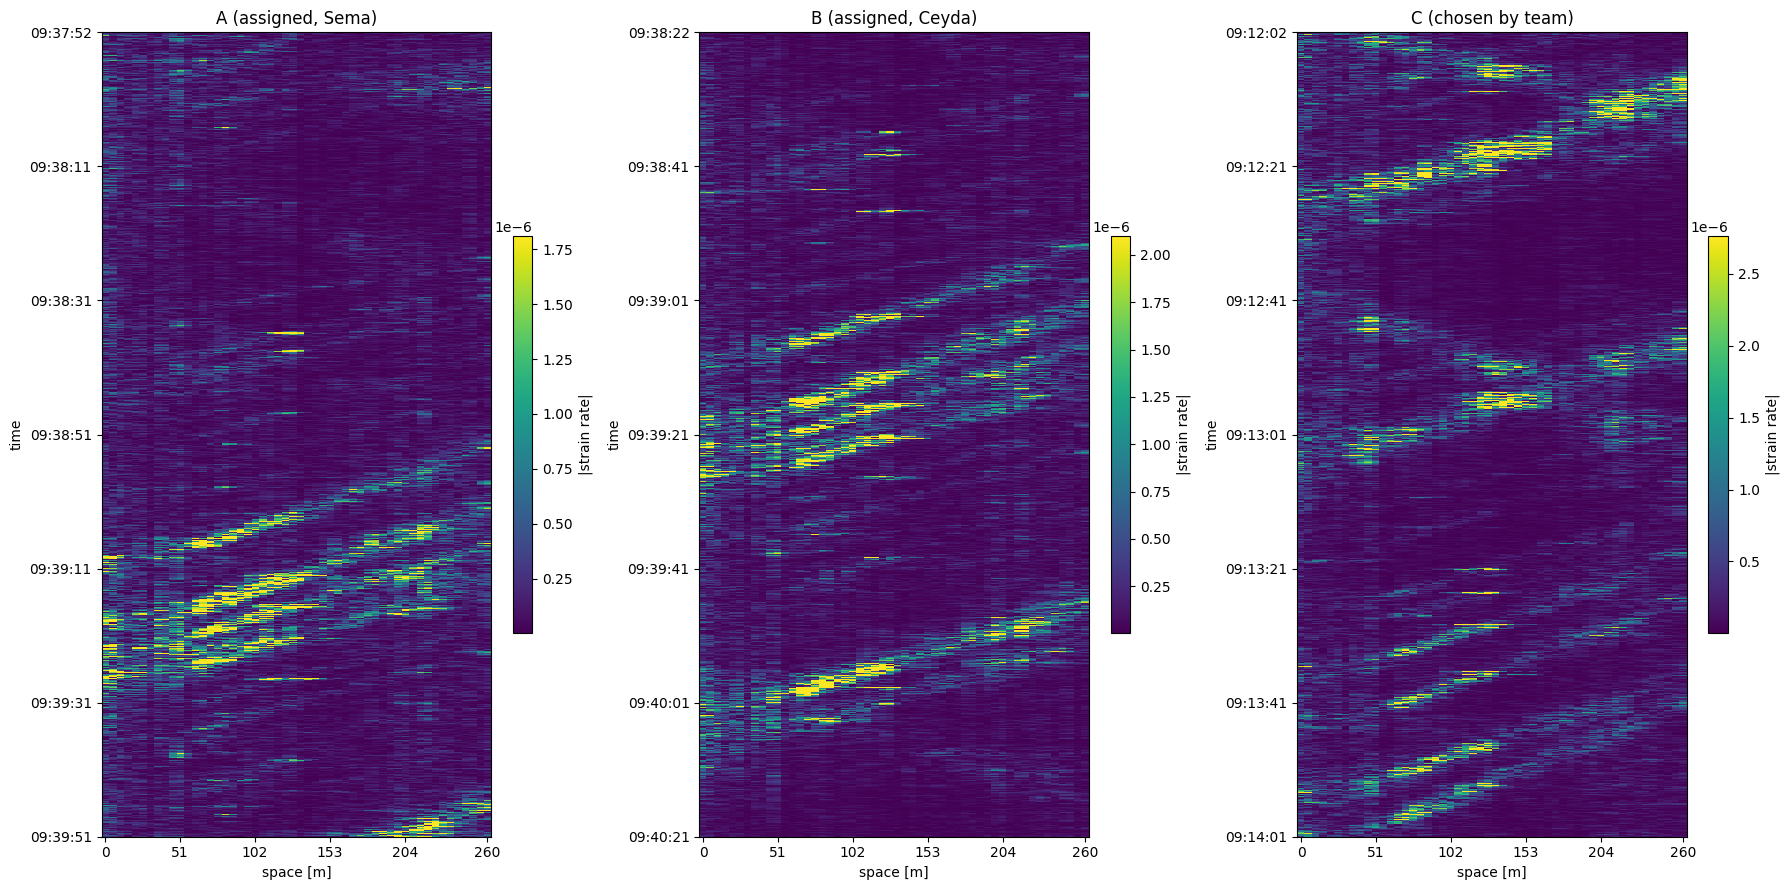

In [5]:
def time_ticks(n_rows, t0, row_dt, n_labels=7):
    """Positions and HH:MM:SS labels for the time (vertical) axis."""
    pos = np.linspace(0, n_rows - 1, n_labels).astype(int)
    labels = [(t0 + datetime.timedelta(seconds=float(p * row_dt))).strftime("%H:%M:%S") for p in pos]
    return pos, labels


def show_das(ax, img, t0, row_dt, title, cmap="viridis", clip=(3, 99)):
    """Display a time x space matrix with time and metre axes."""
    lo, hi = np.percentile(img, clip)
    im = ax.imshow(img, aspect="auto", interpolation="none", cmap=cmap, vmin=lo, vmax=hi)
    pos, labels = time_ticks(img.shape[0], t0, row_dt)
    ax.set_yticks(pos, labels)
    xpos = np.linspace(0, img.shape[1] - 1, 6).astype(int)
    ax.set_xticks(xpos, [f"{p * DX:.0f}" for p in xpos])
    ax.set_xlabel("space [m]")
    ax.set_ylabel("time")
    ax.set_title(title)
    return im


fig, axes = plt.subplots(1, 3, figsize=(18, 9))
for ax, (label, x) in zip(axes, data.items()):
    view = np.abs(x - x.mean(axis=0))
    im = show_das(ax, view, start_time[label], DT, label)
    fig.colorbar(im, ax=ax, fraction=0.046, label="|strain rate|")
plt.tight_layout()
plt.show()

## 3. Keşifsel veri analizi (EDA)

**📄 PDF gereksinimi**

> *"Analyze the dataset. Perform an exploratory analysis of the available data. Calculate basic signal statistics and examine the distribution and variability of signal values across time and space."* (s.5)  
> 🇹🇷 *Veri setini analiz edin. Mevcut veri üzerinde keşifsel analiz yapın. Temel sinyal istatistiklerini hesaplayın ve sinyal değerlerinin zaman ve konum boyunca dağılımını ve değişkenliğini inceleyin.*
>
> *"You may also use the entire available dataset for purposes such as calculating overall signal statistics."* (s.5)  
> 🇹🇷 *Genel sinyal istatistiklerini hesaplamak gibi amaçlarla tüm veri setini de kullanabilirsiniz.*
>
> *"Dataset analysis, including descriptive statistics and visualizations."* (s.6)  
> 🇹🇷 *(Değerlendirme kriteri) Tanımlayıcı istatistikler ve görselleştirmeler dahil veri seti analizi.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Hem **zaman** hem **konum** boyunca değişkenlik incelenmeli (ikisi de isteniyor).
- İstatistikler tüm 259 dosya üzerinde de hesaplanabilir (izinli).
- Grafiklerin eksen adları ve birimleri olmalı.

**🛠️ Yapılacaklar**
- [ ] Temel istatistikler: ortalama, std, min, max, medyan, yüzdelikler
- [ ] Değer dağılımı: histogram
- [ ] Konuma göre değişkenlik: kanal bazında std
- [ ] Zamana göre değişkenlik: zaman bazında std
- [ ] Tüm veride dosya bazında aktivite → C seçiminin gerekçesi
- [ ] A, B, C ve tüm verinin karşılaştırması

**📝 Rapora girecekler**
- İstatistik özeti
- Histogram
- Kanal-std ve zaman-std grafikleri
- Yorum: hangi kanallar gürültülü, yatay gürültü var mı

**Sonuç / yorum:** _(doldurulacak)_

## 4. Frekans analizi

**📄 PDF gereksinimi**

> *"Perform a frequency analysis of the signal. Remember that the FFT should be applied independently to each channel."* (s.5)  
> 🇹🇷 *Sinyalin frekans analizini yapın. FFT'nin her kanala ayrı ayrı uygulanması gerektiğini unutmayın.*
>
> *"You may also use time-frequency analysis methods, such as the Short-Time Fourier Transform (STFT), to investigate how the frequency content changes over time."* (s.5)  
> 🇹🇷 *Frekans içeriğinin zamanla nasıl değiştiğini incelemek için Kısa Zamanlı Fourier Dönüşümü (STFT) gibi zaman-frekans yöntemlerini de kullanabilirsiniz.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- FFT **her kanala ayrı** uygulanmalı (zaman ekseni boyunca); tüm matris tek sinyal gibi düzleştirilmemeli.
- fs = 625 Hz → görülebilecek en yüksek frekans 312.5 Hz (Nyquist).
- Filtre bandı **buradaki sonuçlara dayanarak** seçilecek ve gerekçesi yazılacak.

**🛠️ Yapılacaklar**
- [ ] Her kanala FFT → ortalama spektrum
- [ ] Frekans × kanal güç haritası
- [ ] Araç geçen ve sakin anların spektrum karşılaştırması
- [ ] Bir kanalın spektrogramı (STFT)
- [ ] Filtre bandına karar ver

**📝 Rapora girecekler**
- Spektrum grafikleri
- Spektrogram
- Seçilen frekans bandı ve gerekçesi

**Sonuç / yorum:** _(doldurulacak)_

## 5. Algoritmanın akış şeması

**📄 PDF gereksinimi**

> *"Prepare a block diagram or flowchart illustrating the proposed algorithm and its main processing steps. Include a description of each step and explain its purpose."* (s.5)  
> 🇹🇷 *Önerilen algoritmayı ve ana işleme adımlarını gösteren bir blok diyagram veya akış şeması hazırlayın. Her adımın açıklamasını ekleyin ve amacını anlatın.*
>
> *"Block diagram or flowchart of the algorithm, with descriptions of the main processing steps."* (s.6)  
> 🇹🇷 *(Değerlendirme kriteri) Ana işleme adımlarının açıklamalarıyla birlikte algoritmanın blok diyagramı veya akış şeması.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Her kutu için: **ne yapıyor + neden gerekli**.
- Algoritma bitince son haline göre çizilecek (Bölüm 6–9).

**🛠️ Yapılacaklar**
- [ ] Akış şemasını çiz
- [ ] Her adımın kısa açıklamasını yaz

**📝 Rapora girecekler**
- Akış şeması resmi
- Adım açıklamaları

**Sonuç / yorum:** _(doldurulacak)_

## 6. Gürültü filtreleme

**📄 PDF gereksinimi**

> *"Filter out the noise, which may include: removing unnecessary frequency components, downsampling, applying appropriate filters, standardization or rescaling of the data, and any other preprocessing steps you find useful."* (s.5)  
> 🇹🇷 *Gürültüyü filtreleyin. Bu şunları içerebilir: gereksiz frekans bileşenlerini kaldırmak, örnek seyreltme (downsampling), uygun filtreler uygulamak, verileri standartlaştırmak veya yeniden ölçeklemek ve faydalı bulduğunuz diğer ön işleme adımları.*
>
> *"Visualizations of individual processing steps, showing the data before and after each operation, including detected objects and noise or signal components removed or suppressed."* (s.6)  
> 🇹🇷 *(Değerlendirme kriteri) Her işlemden önceki ve sonraki veriyi gösteren, tespit edilen nesneleri ve kaldırılan veya bastırılan gürültü/sinyal bileşenlerini de içeren işlem adımı görselleri.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Her işlemden sonra **önce/sonra resmi** + mümkünse **çıkarılan gürültünün** resmi.
- Frekans bandı Bölüm 4'e dayanmalı.
- Downsampling sonrası **yeni dt** kullanılmalı (hız hesabı için kritik).
- Filtreler NumPy/OpenCV/skimage ile yapılmalı (SciPy yok).

**🛠️ Yapılacaklar**
- [ ] 6.1 Gereksiz frekansları kaldırma (bant geçiren filtre)
- [ ] 6.2 Ortak gürültüyü (yatay çizgileri) kaldırma
- [ ] 6.3 Downsampling
- [ ] 6.4 Standartlaştırma / yeniden ölçekleme
- [ ] 6.5 (Gerekirse) ek filtreler

**📝 Rapora girecekler**
- Her alt adım için önce/sonra görselleri
- Seçilen parametreler ve gerekçeleri

**Sonuç / yorum:** _(doldurulacak)_

## 7. Sadece eğik çizgileri (hareketli nesneleri) bırakma

**📄 PDF gereksinimi**

> *"Process the data so that only moving objects (slanted lines) are visible."* (s.5)  
> 🇹🇷 *Veriyi, yalnızca hareketli nesneler (eğik çizgiler) görünecek şekilde işleyin.*
>
> *"You may have multiple processing paths responsible for detecting or filtering different elements in an image."* (s.5)  
> 🇹🇷 *Resimdeki farklı öğeleri tespit etmekten veya filtrelemekten sorumlu birden fazla işleme yolunuz olabilir.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Eşik **otomatik** seçilmeli (ör. Otsu); elle sabit sayı hardcode sayılabilir.
- Yatay ve dikey yapılar araç değildir, elenmeli.
- Bilinen görüntü işleme teknikleri kullanılmalı. (s.6: *"Proper use of established image processing techniques"* 🇹🇷 *yerleşik görüntü işleme tekniklerinin doğru kullanımı*)

**🛠️ Yapılacaklar**
- [ ] Yumuşatma
- [ ] Otomatik eşikleme → ikili maske
- [ ] Morfoloji (açma / kapama)
- [ ] Küçük ve yanlış bileşenleri eleme

**📝 Rapora girecekler**
- Her işlemin önce/sonra görseli
- Son maske

**Sonuç / yorum:** _(doldurulacak)_

## 8. Çizgi tespiti ve hız hesabı

**📄 PDF gereksinimi**

> *"Determine the velocity of these objects (see the figure on the next page for reference)."* (s.5)  
> 🇹🇷 *Bu nesnelerin hızını belirleyin (referans için sonraki sayfadaki şekle bakın).*
>
> *"If your algorithm detects many potential line candidates, you can group these lines and extract the average line from the group."* (s.5)  
> 🇹🇷 *Algoritmanız çok sayıda aday çizgi bulursa bu çizgileri gruplayıp gruptan ortalama çizgiyi çıkarabilirsiniz.*
>
> *"you cannot directly hardcode the position of lines or any elements directly related to specific individual lines."* (s.5)  
> 🇹🇷 *çizgilerin konumunu veya tek tek belirli çizgilerle doğrudan ilgili hiçbir öğeyi koda doğrudan yazamazsınız.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Hız = (Δkanal × dx) / (Δsatır × dt) × 3.6 → km/h. dt = downsampling sonrası dt.
- Aynı araca ait çizgiler **gruplanıp tek çizgiye** indirilmeli.
- Gerçekçi olmayan hızlar fiziksel gerekçeyle elenebilir (hardcode değil, genel kural).
- Tespit edilen nesnelerin sayısı ve doğruluğu puanlanıyor. (s.6: *"Number and accuracy of detected objects."* 🇹🇷 *Tespit edilen nesnelerin sayısı ve doğruluğu.*)

**🛠️ Yapılacaklar**
- [ ] Hough dönüşümü ile aday çizgiler
- [ ] Çizgileri grupla → ortalama çizgi
- [ ] Eğimden hız
- [ ] Yön (+ / −)

**📝 Rapora girecekler**
- PDF s.2'deki örnek şekil gibi: resim üstünde çizgiler + km/h etiketleri

**Sonuç / yorum:** _(doldurulacak)_

## 9. İnce (zayıf) çizgiler

**📄 PDF gereksinimi**

> *"On the images, there are clearly visible thick, strong lines (corresponding to the passage of a tram or a heavy truck) and fainter, thinner lines (corresponding to individual cars). To receive a grade of 3/4, it is sufficient to detect the thick, clearly visible lines. To receive a grade of 5, you must also detect the thinner, weaker lines."* (s.6)  
> 🇹🇷 *Resimlerde açıkça görünen kalın, güçlü çizgiler (tramvay veya ağır kamyon geçişi) ve daha soluk, ince çizgiler (tek tek otomobiller) var. 3/4 notu için kalın, belirgin çizgileri tespit etmek yeterli. 5 notu için ince, zayıf çizgileri de tespit etmelisiniz.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- 4 için kalın çizgiler yeterli; 5 için ince çizgiler de gerekli.
- Ayrı işleme yolu kullanılabilir. (s.5: *"multiple processing paths"* 🇹🇷 *birden fazla işleme yolu*)
- Yine hardcode yok; aynı yöntem tüm aralıklarda çalışmalı.

**🛠️ Yapılacaklar**
- [ ] Kalın çizgileri maskele
- [ ] Daha hassas ikinci yolla soluk çizgileri ara
- [ ] Sonuçları birleştir

**📝 Rapora girecekler**
- Kalın / ince çizgi ayrımı görselleri

**Sonuç / yorum:** _(doldurulacak)_

## 10. Ekstra puan (isteğe bağlı)

**📄 PDF gereksinimi**

> *"Instead of providing only a single value for each object's speed, plot a graph showing how the velocity changes over time."* (s.6)  
> 🇹🇷 *Her nesnenin hızı için yalnızca tek bir değer vermek yerine, hızın zamanla nasıl değiştiğini gösteren bir grafik çizin.*
>
> *"perform clustering of the detected objects into several groups that differ in the characteristics of their signals, for example: thick lines, thin lines, objects moving at a constant speed, objects with varying speed, shape of the lines"* (s.6)  
> 🇹🇷 *tespit edilen nesneleri sinyal özellikleri farklı olan birkaç gruba kümeleyin; örneğin: kalın çizgiler, ince çizgiler, sabit hızla hareket edenler, hızı değişenler, çizgilerin şekli*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Zorunlu değil; ana adımlar bittikten sonra yapılacak.
- Kümeleme izinli kütüphanelerle yapılmalı (ör. OpenCV k-means).

**🛠️ Yapılacaklar**
- [ ] Hız–zaman grafiği
- [ ] Özellik çıkarma (kalınlık, parlaklık, hız, hız değişimi)
- [ ] Kümeleme

**📝 Rapora girecekler**
- Hız–zaman grafikleri
- Küme görselleri ve yorum

**Sonuç / yorum:** _(doldurulacak)_

## 11. Üç aralığın sonuçları

**📄 PDF gereksinimi**

> *"Detailed results for three 2-minute time segments"* (s.6)  
> 🇹🇷 *Üç adet 2 dakikalık zaman aralığı için ayrıntılı sonuçlar*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- **Aynı algoritma ve aynı parametreler** üç aralığa da uygulanmalı (genel yaklaşım).
- Sonuçlar gözle kontrol edilmeli (gerçek veride cevap anahtarı yok, s.2).

**🛠️ Yapılacaklar**
- [ ] A, B, C için algoritmayı çalıştır
- [ ] Sonuç resimleri
- [ ] Araç tablosu

**📝 Rapora girecekler**
- Her aralık için: sonuç resmi + araç listesi (zaman, yön, hız, kalın/ince)
- Toplam araç sayıları

**Sonuç / yorum:** _(doldurulacak)_

## 12. Denenen yöntemler

**📄 PDF gereksinimi**

> *"a report describing the algorithm along with a description of intermediate steps and the experiments performed (if you have tested several successful/unsuccessful solutions, describe them)"* (s.4)  
> 🇹🇷 *algoritmayı, ara adımların açıklamasını ve yapılan deneyleri anlatan bir rapor (birkaç başarılı/başarısız çözüm denediyseniz onları da anlatın)*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Başarısız denemeler de yazılmalı; puan getirir.
- Proje boyunca not alınacak.

**🛠️ Yapılacaklar**
- [ ] Her denemeyi kısaca not al: ne denendi, sonuç ne oldu, neden vazgeçildi

**📝 Rapora girecekler**
- Denemeler listesi

**Sonuç / yorum:** _(doldurulacak)_

## 13. Sonuçlar ve yorum

**📄 PDF gereksinimi**

> *"Analysis and conclusions based on the obtained results."* (s.7)  
> 🇹🇷 *Elde edilen sonuçlara dayanan analiz ve çıkarımlar.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Yorumlar sonuçlara dayanmalı.

**🛠️ Yapılacaklar**
- [ ] Bulunan araç sayısı, hız aralıkları, aralıklar arası farklar

**📝 Rapora girecekler**
- Kısa sonuç paragrafı

**Sonuç / yorum:** _(doldurulacak)_

## 14. Hatalar ve sınırlamalar

**📄 PDF gereksinimi**

> *"Identification of factual and methodological errors and limitations."* (s.7)  
> 🇹🇷 *Olgusal ve yöntemsel hataların ve sınırlamaların belirlenmesi.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Dürüst olunmalı: yöntemin nerede başarısız olduğu yazılmalı.

**🛠️ Yapılacaklar**
- [ ] Örnekler: üst üste binen araçlar, çok soluk çizgiler, gürültülü kanallar, ground truth olmaması

**📝 Rapora girecekler**
- Sınırlamalar listesi

**Sonuç / yorum:** _(doldurulacak)_

## 15. Kaynaklar

**📄 PDF gereksinimi**

> *"All sources of data, code and inspiration must be reported with a description of what was used."* (s.4)  
> 🇹🇷 *Kullanılan tüm veri, kod ve ilham kaynakları, neyin kullanıldığı açıklanarak belirtilmelidir.*
>
> *"References to relevant literature and other sources."* (s.7)  
> 🇹🇷 *İlgili literatüre ve diğer kaynaklara atıflar.*

**⚠️ Dikkat edilecekler (hocanın kuralları)**
- Her kaynak için **ne kullanıldığı** yazılmalı.

**🛠️ Yapılacaklar**
- [ ] Kaynak listesini proje boyunca güncelle

**📝 Rapora girecekler**
- Proje açıklaması (Project 1 2026.pdf)
- Gerçek DAS verisi (20240507, Jana Pawla II)
- Örnek notebook *DAS file overview.ipynb* → veri yükleme ve gösterim (Bölüm 2)
- _(eklenecek)_

**Sonuç / yorum:** _(doldurulacak)_

## ✅ Teslim kontrol listesi _(teslimden önce silinecek)_

> *"The solution can be presented in the form of source code (.py) and an attached report (.pdf) or a jupyter notebook file (.ipynb and one of .pdf or .html) containing the code and description of the next steps"* (s.4)  
> 🇹🇷 *Çözüm, kaynak kod (.py) ve ekli rapor (.pdf) şeklinde ya da kodu ve adımların açıklamasını içeren bir Jupyter notebook dosyası (.ipynb ve .pdf veya .html'den biri) şeklinde sunulabilir*
>
> *"Deadline for sending the code, and report: 22.11.2026 23:59"* (s.4)  
> 🇹🇷 *Kodun ve raporun gönderilmesi için son tarih: 22.11.2026 23:59*

- [ ] Notebook baştan sona **hatasız ve uyarısız** çalışıyor
- [ ] Sadece izinli kütüphaneler
- [ ] Hardcode yok
- [ ] Üç aralığın sonuçları var
- [ ] Akış şeması var
- [ ] Her adımın önce/sonra görselleri var
- [ ] Kaynaklar tamam
- [ ] İngilizceye çevrildi
- [ ] `.ipynb` + `.html` (veya `.pdf`) dışa aktarıldı
- [ ] 22.11.2026 23:59'dan önce gönderildi